# Université Paul Sabatier
# M1 IAFA - Foundations of Information Retrieval - 2026

Instructors: Lynda Tamine, Karim Radouane and Ahmed Rayane Kebir

---

💡 Consider developing auxiliary scripts and functions that will enable you to reuse recurring commands in this practical work (PW) and future ones. This would help you keeping good code practice and make debugging easier.


### Attention❗ About TP grading:
🚨 *Code questions*: Fill in the missing code in the corresponding sections (commented code gets the best marks).

🚨 *Open questions*: Write your textual answer as a comment in the corresponding cells.

🚨 *Keep your outputs*: **Empty outputs (notebook or non-executed cells) correspond to 0 points**.

---

# TP 2: Traditional Information Retrieval with PyTerrier

## Inverted Indexing and Evaluation

Information Retrieval (IR) systems are essential for processing and retrieving relevant information from **large collections of text**. In this PW, we will build on concepts introduced in the previous lab work to construct an **inverted index**, execute **queries**, and evaluate **retrieval models** using PyTerrier (Terrier Python version).


### Objectives


Through this PW, you will:

1. Build an inverted index for a given document corpus.
2. Perform queries using term-weighting methods.
3. Evaluate different retrieval models using standard IR metrics.
4. Design experimental pipelines to compare retrieval models.

This lab extends the toy indexing system from the previous session to work with a **larger dataset** and introduces a structured evaluation framework to assess retrieval performance.

## Installations and Setup

Installing a framework like Terrier or PyTerrier can be complicated. However, its creators have decided to simplify many of the installation tasks. To this end, we will perform a simple installation using pip on Python.

PyTerrier automates many of the indexing and retrieval processes, making it easy to experiment with different configurations.

> 👉 This PW only requires a *CPU runtime*.

In [1]:
import os
os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-17-openjdk-amd64'
!export JAVA_HOME=/usr/lib/jvm/java-17-openjdk-amd64

In [2]:
# Some libraries to use later
!pip install python-terrier
!pip install scikit-learn matplotlib
!pip install datasets

  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.8/208.8 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 866.1/866.1 kB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 304.8/304.8 kB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.7/149.7 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 4.0 MB/s eta 0:00:00
  Created wheel for warc3-wet-clueweb09: filename=warc3_wet_clueweb09-0.2.5-py3-none-any.whl size=18919 sha256=ed353eb50af60cbf74d7e3f42b77791a56e1b1c37e10fd4a8dbc998c7a16784e
  Stored in directory: /root/.cache/pip/wheels/f6/85/c2/9f0f621def52a1d5db7d29984f81e45f9fb6dfeb1a4eb6e31c
 

In [3]:
#Initialization de JVM
import pyterrier as pt
if not pt.started():
  pt.init(tqdm='notebook')

terrier-assemblies 5.11 jar-with-dependencies not found, downloading to /root/.pyterrier...


/tmp/ipykernel_12948/4259357799.py:3: DeprecationWarning: Call to deprecated function (or staticmethod) started. (use pt.java.started() instead) -- Deprecated since version 0.11.0.
  if not pt.started():


https://repo1.maven.org/maven2/org/terrier/terrier-assemblies/5.11/terrier-assemblies-5.11-jar-with-dependenci…

Done
terrier-python-helper 0.0.8 jar not found, downloading to /root/.pyterrier...


https://repo1.maven.org/maven2/org/terrier/terrier-python-helper/0.0.8/terrier-python-helper-0.0.8.jar:   0%| …

Done


Java started and loaded: pyterrier.java.colab, pyterrier.java, pyterrier.java.24, pyterrier.terrier.java [version=5.11 (build: craig.macdonald 2025-01-13 21:29), helper_version=0.0.8]
/tmp/ipykernel_12948/4259357799.py:4: DeprecationWarning: Call to deprecated method pt.init(). Deprecated since version 0.11.0.
The following code will have the same effect:
pt.utils.set_tqdm('notebook')
pt.java.init() # optional, forces java initialisation
  pt.init(tqdm='notebook')


# I. Indexing

Indexing is a crucial step in IR, as it allows the system to efficiently store and retrieve documents.




## 1. Collecting the Document Corpus
*(Refer to slides 15 and 16 for theoretical concepts)*

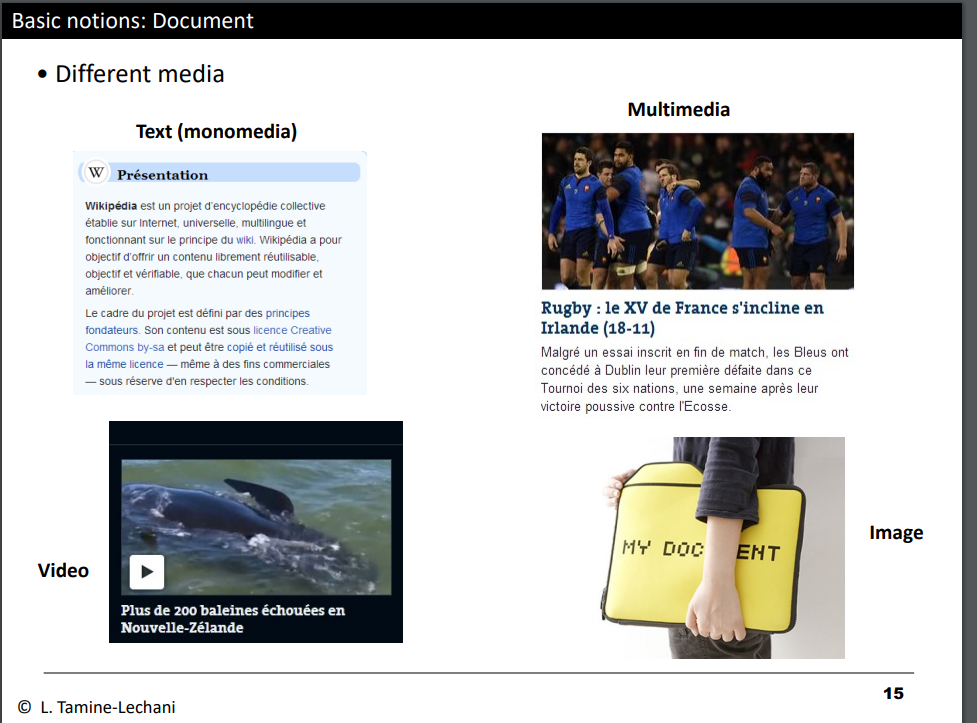

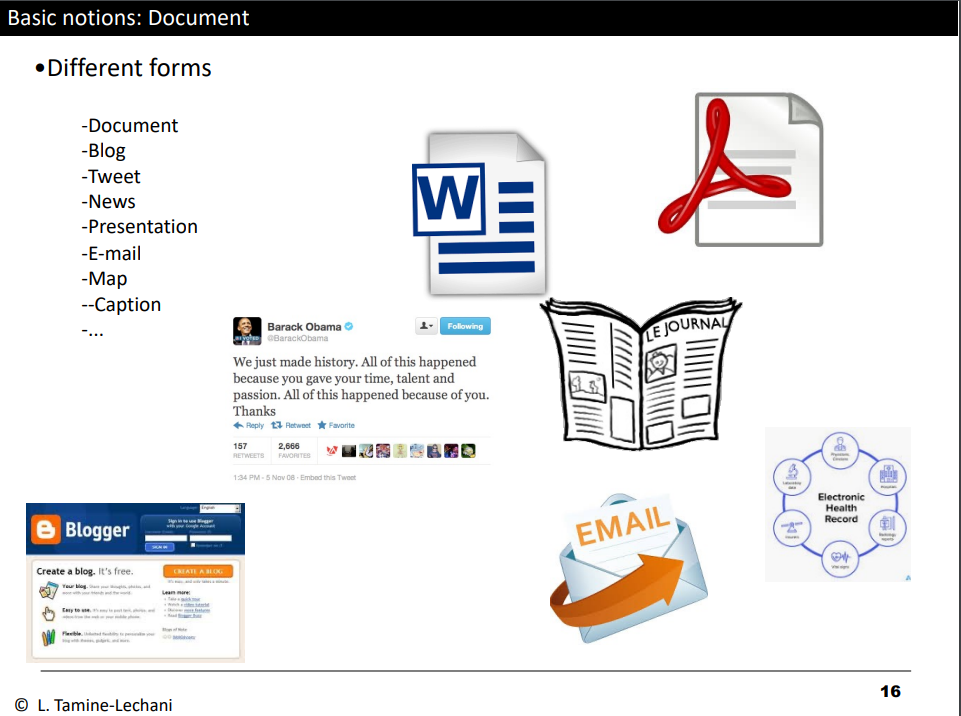

There are corpora of text documents available for free download hosted on [Datasets from HuggingFaces](https://huggingface.co/docs/datasets/index) and [Pyterrier](https://pyterrier.readthedocs.io/en/latest/datasets.html#available-datasets)

In the previous PW, we used a toy version of the *CORD19* dataset. Here, we will work with the *full* version.

We can gather the data with the following lines:


In [4]:
dataset = pt.datasets.get_dataset('irds:cord19/trec-covid')
topics = dataset.get_topics(variant='description')

[INFO] [starting] https://ir.nist.gov/covidSubmit/data/topics-rnd5.xml
[INFO] [finished] https://ir.nist.gov/covidSubmit/data/topics-rnd5.xml: [00:00] [18.7kB] [9.94MB/s]


## 2. Building an Inverted Index
**(Refer to class material for details.)**

In the previous PW, each document was stored as an independent variable or representation. However, this approach is inefficient for large-scale search tasks. Instead, an **inverted index** allows us to:
- Reduce computational costs for large-scale search.
- Enable efficient document retrieval through structured term-document mapping.


Let's start by printing a sample entry of the dataset. As you can see, each entry is in JSON format with different information fields.

In [5]:
next(iter(dataset.get_corpus_iter()))

[INFO] [starting] building docstore
[INFO] If you have a local copy of https://ai2-semanticscholar-cord-19.s3-us-west-2.amazonaws.com/2020-07-16/metadata.csv, you can symlink it here to avoid downloading it again: /root/.ir_datasets/downloads/80d664e496b8b7e50a39c6f6bb92e0ef
[INFO] [starting] https://ai2-semanticscholar-cord-19.s3-us-west-2.amazonaws.com/2020-07-16/metadata.csv
docs_iter:   0%|                                    | 0/192509 [00:00<?, ?doc/s]
https://ai2-semanticscholar-cord-19.s3-us-west-2.amazonaws.com/2020-07-16/metadata.csv: 0.0%| 0.00/269M [00:00<?, ?B/s]
https://ai2-semanticscholar-cord-19.s3-us-west-2.amazonaws.com/2020-07-16/metadata.csv: 0.0%| 65.5k/269M [00:00<08:09, 550kB/s]
https://ai2-semanticscholar-cord-19.s3-us-west-2.amazonaws.com/2020-07-16/metadata.csv: 0.1%| 377k/269M [00:00<02:56, 1.52MB/s]
https://ai2-semanticscholar-cord-19.s3-us-west-2.amazonaws.com/2020-07-16/metadata.csv: 0.6%| 1.61M/269M [00:00<01:02, 4.28MB/s]
https://ai2-semanticscholar-cord-

cord19/trec-covid documents:   0%|          | 0/192509 [00:00<?, ?it/s]

{'title': 'Clinical features of culture-proven Mycoplasma pneumoniae infections at King Abdulaziz University Hospital, Jeddah, Saudi Arabia',
 'doi': '10.1186/1471-2334-1-6',
 'date': '2001-07-04',
 'abstract': 'OBJECTIVE: This retrospective chart review describes the epidemiology and clinical features of 40 patients with culture-proven Mycoplasma pneumoniae infections at King Abdulaziz University Hospital, Jeddah, Saudi Arabia. METHODS: Patients with positive M. pneumoniae cultures from respiratory specimens from January 1997 through December 1998 were identified through the Microbiology records. Charts of patients were reviewed. RESULTS: 40 patients were identified, 33 (82.5%) of whom required admission. Most infections (92.5%) were community-acquired. The infection affected all age groups but was most common in infants (32.5%) and pre-school children (22.5%). It occurred year-round but was most common in the fall (35%) and spring (30%). More than three-quarters of patients (77.5%) h

We now proceed to index the complete dataset (code below)

The task seems trivial, but the PyTerrier framework does most of the work. For more details, on how to create an index and the parameters to use, refer to the [documentation](https://pyterrier.readthedocs.io/en/latest/terrier-indexing.html).

In [6]:
# Index the collection
!rm -rf ./terrier_cord19/

pt_index_path = './terrier_cord19'

if not os.path.exists(pt_index_path + "/data.properties"):
    # create the index, using the IterDictIndexer indexer
    indexer = pt.index.IterDictIndexer(pt_index_path, text_attrs=['abstract'], meta=['title','docno'])

    # we give the dataset get_corpus_iter() directly to the indexer
    # while specifying the fields to index and the metadata to record
    # index_ref = indexer.index(cord19.get_corpus_iter(),
    #                           text_attrs=['abstract'])
    indexref = indexer.index(dataset.get_corpus_iter(), )

else:
    # if you already have the index, use it.
    indexref = pt.IndexRef.of(pt_index_path + "/data.properties")

index = pt.IndexFactory.of(indexref)

cord19/trec-covid documents:   0%|          | 0/192509 [00:00<?, ?it/s]

20:11:27.258 [ForkJoinPool-1-worker-1] WARN org.terrier.structures.indexing.Indexer -- Adding an empty document to the index (6iu1dtyl) - further warnings are suppressed
20:12:47.636 [ForkJoinPool-1-worker-1] ERROR org.terrier.structures.indexing.Indexer -- Could not finish MetaIndexBuilder: 
java.io.IOException: Key 8lqzfj2e is not unique: 37597,11755
For MetaIndex, to suppress, set metaindex.compressed.reverse.allow.duplicates=true
	at org.terrier.structures.collections.FSOrderedMapFile$MultiFSOMapWriter.mergeTwo(FSOrderedMapFile.java:1374)
	at org.terrier.structures.collections.FSOrderedMapFile$MultiFSOMapWriter.close(FSOrderedMapFile.java:1308)
	at org.terrier.structures.indexing.BaseMetaIndexBuilder.close(BaseMetaIndexBuilder.java:321)
	at org.terrier.structures.indexing.classical.BasicIndexer.indexDocuments(BasicIndexer.java:270)
	at org.terrier.structures.indexing.classical.BasicIndexer.createDirectIndex(BasicIndexer.java:388)
	at org.terrier.structures.indexing.Indexer.index(In

From the given code, we can notice that the most important line is
> indexer = pt.index.IterDictIndexer(pt_index_path, text_attrs=['abstract'], meta=['title','docno'])

Where:
- `text_attrs=['abstract']`: Defines the content used for indexing and search.
- `meta=['title','docno']`: Specifies additional metadata stored in the index.


📌 Note that the `./terrier_cord19` folder will be created to store the index. Ensure you save it if you need persistent storage.




####  Question ✍ OK
1. What are the statistics of the created index? (refer to the documentation to answer)

In [7]:
print(index.getCollectionStatistics())

Number of documents: 192509
Number of terms: 151235
Number of postings: 11554033
Number of fields: 0
Number of tokens: 17728468
Field names: []
Positions:   false



The statistics of the created index are:

Number of documents: 192509

Number of terms: 151235

Number of postings: 11554033

Number of fields: 0

Number of tokens: 17728468

Field names: []

Positions:   false

####  Question ✍ OK
2. List the files inside `terrier_cord19`.
  - Use the function `getLexicon()` from the index to print the vocabulary and the function `getValue().toString()` to print the content of each word in our vocabulary. Print only 20 words to simplify the output.
  - What is the meaning of `Nt`, `TF` and `maxTF`? (refer to class material if needed)

In [8]:
# 1. List the files inside 'terrier_cord19'
print("Files inside 'terrier_cord19':")

print(os.listdir("terrier_cord19"))
print("-" * 50)

# 2. Print 20 words using getLexicon() and getValue().toString()
print("Vocabulary sample (20 words):")
lexicon = index.getLexicon()

count = 0
for term, le in lexicon: # le = lexicon entry
    print(f"Word: {term} | Content: {le.toString()}")
    count += 1
    if count == 20:
        break

Files inside 'terrier_cord19':
['data.meta-0.fsomapfile.6', 'data.meta-0.fsomapfile.2', 'data.meta-0.fsomapfile.-1', 'data.meta-0.fsomapfile.7', 'data.properties', 'data.lexicon.fsomaphash', 'data.lexicon.fsomapid', 'data.meta-0.fsomapfile.8', 'data.meta.idx', 'data.document.fsarrayfile', 'data.meta-0.fsomapfile.1', 'data.meta.zdata', 'data.meta-0.fsomapfile.0', 'data.lexicon.fsomapfile', 'data.meta-0.fsomapfile.9', 'data.direct.bf', 'data.meta-0.fsomapfile.5', 'data.meta-0.fsomapfile.3', 'data.meta-0.fsomapfile.4', 'data.inverted.bf']
--------------------------------------------------
Vocabulary sample (20 words):
Word: 0 | Content: term23 Nt=27012 TF=103854 maxTF=2147483647 @{0 0 0}
Word: 00 | Content: term3624 Nt=1046 TF=1577 maxTF=2147483647 @{0 28173 6}
Word: 000 | Content: term1007 Nt=4054 TF=6391 maxTF=2147483647 @{0 30007 3}
Word: 0001 | Content: term4184 Nt=1557 TF=2560 maxTF=2147483647 @{0 35483 0}
Word: 0002 | Content: term12960 Nt=138 TF=150 maxTF=2147483647 @{0 38028 1}
Wo

- Nt (Document Frequency): The number of unique documents in the entire collection that contain this specific term.

- TF (Collection Term Frequency): The total number of occurrences of the term across all documents in the entire indexed collection.

- maxTF (Maximum Term Frequency): The maximum number of times this term appears in any single document within the collection.

####  Question ✍ OK

3. You might notice that `getLexicon()` returns a Dictionary where the key is the stored word. The code below provides a pointer to the word `vaccine` in our index.

Iterate the different postings list for this word using the line `getInvertedIndex().getPostings(pointer)`. Print the `ID`, `TF`, and `doclen` for each document, and provide the meaning of these elements.

In [9]:
pointer = index.getLexicon()["vaccine"]
pointer.toString()

'term7406 Nt=38 TF=52 maxTF=2147483647 @{0 15467742 2}'

In [10]:
# Get the inverted index and the postings list for the pointer
postings = index.getInvertedIndex().getPostings(pointer)

# Iterate through the postings list
# postings.next() moves to the next document and returns its ID. It returns EOL when finished.
while postings.next() != postings.EOL:
    doc_id = postings.getId()
    tf = postings.getFrequency()
    doclen = postings.getDocumentLength()

    print(f"ID: {doc_id} | TF: {tf} | doclen: {doclen}")

ID: 579 | TF: 1 | doclen: 198
ID: 965 | TF: 1 | doclen: 189
ID: 1710 | TF: 1 | doclen: 145
ID: 2153 | TF: 1 | doclen: 218
ID: 2226 | TF: 1 | doclen: 178
ID: 2522 | TF: 1 | doclen: 154
ID: 4629 | TF: 1 | doclen: 299
ID: 4903 | TF: 7 | doclen: 251
ID: 6884 | TF: 1 | doclen: 108
ID: 7490 | TF: 1 | doclen: 121
ID: 7521 | TF: 1 | doclen: 106
ID: 11685 | TF: 1 | doclen: 136
ID: 12613 | TF: 1 | doclen: 164
ID: 13338 | TF: 1 | doclen: 230
ID: 21242 | TF: 1 | doclen: 236
ID: 31814 | TF: 1 | doclen: 246
ID: 48699 | TF: 1 | doclen: 118
ID: 50786 | TF: 1 | doclen: 212
ID: 63003 | TF: 2 | doclen: 72
ID: 70390 | TF: 1 | doclen: 110
ID: 84467 | TF: 5 | doclen: 158
ID: 134389 | TF: 1 | doclen: 170
ID: 134910 | TF: 1 | doclen: 122
ID: 136727 | TF: 1 | doclen: 77
ID: 141767 | TF: 1 | doclen: 183
ID: 143083 | TF: 1 | doclen: 260
ID: 144498 | TF: 1 | doclen: 89
ID: 145001 | TF: 2 | doclen: 172
ID: 146486 | TF: 1 | doclen: 231
ID: 150266 | TF: 1 | doclen: 203
ID: 152104 | TF: 1 | doclen: 99
ID: 160373 | TF

- ID (Document ID): The internal, unique integer identifier assigned to a specific document by PyTerrier during the indexing process.

- TF (Term Frequency): The number of times the exact word (in this case "vaccine") appears in this specific document.

- doclen (Document Length): The total number of tokens (words) contained in this specific document. This is useful for retrieval models like BM25 that penalize term frequencies in very long documents.

# II. Querying and Retrieval Models

Now that we have an index, we can perform search queries and retrieve relevant documents using the BatchRetrieve object from PyTerrier.

For our example, we will use the `TF-IDF` retrieval model (code below), specified in the `wmodel` param.

> Notice that the output is in DataFrame format.

In [11]:
pt.BatchRetrieve(index, wmodel="TF_IDF").search("vaccine")

/tmp/ipykernel_12948/2414491301.py:1: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  pt.BatchRetrieve(index, wmodel="TF_IDF").search("vaccine")


,qid,docid,docno,rank,score,query
0,1,29970,jwd96s79,0,4.785799,vaccine
1,1,82260,91rm1uvs,1,4.749890,vaccine
2,1,51059,xhe9nuvt,2,4.726156,vaccine
3,1,175627,4xkux5z4,3,4.715711,vaccine
4,1,134087,j93f6eso,4,4.698982,vaccine
...,...,...,...,...,...,...
995,1,7668,5hifn0cf,995,4.170605,vaccine
996,1,11567,t3eeks1n,996,4.170605,vaccine
997,1,16687,i2a6nix7,997,4.170605,vaccine
998,1,87694,7ykbbax6,998,4.170605,vaccine


Also, we can specify `metadata=["docno", "title"]` to display relevant fields in results.

In [12]:
pt.BatchRetrieve(index, wmodel="TF_IDF", metadata=["docno","title"]).search("vaccine")

/tmp/ipykernel_12948/3346125598.py:1: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  pt.BatchRetrieve(index, wmodel="TF_IDF", metadata=["docno","title"]).search("vaccine")


,qid,docid,docno,title,rank,score,query
0,1,29970,jwd96s79,Combined infectious bronchitis virus Arkansas ...,0,4.785799,vaccine
1,1,82260,91rm1uvs,Efficacy of two canine parvovirus vaccines for...,1,4.749890,vaccine
2,1,51059,xhe9nuvt,Efficacy of intradermally administrated E2 sub...,2,4.726156,vaccine
3,1,175627,4xkux5z4,Recent Advances in Vaccine Technologies,3,4.715711,vaccine
4,1,134087,j93f6eso,What influenza vaccination programmes are pref...,4,4.698982,vaccine
...,...,...,...,...,...,...,...
995,1,7668,5hifn0cf,Population implications of the deployment of n...,995,4.170605,vaccine
996,1,11567,t3eeks1n,Vaccination against the Epstein–Barr virus,996,4.170605,vaccine
997,1,16687,i2a6nix7,Economic Implications of Influenza and Influen...,997,4.170605,vaccine
998,1,87694,7ykbbax6,Ii-Key/MHC class II epitope hybrids: a strateg...,998,4.170605,vaccine


Other models are available. They are described in [Pyterrier](https://pyterrier.readthedocs.io/en/latest/terrier-retrieval.html#terrier-configuration) or [Terrier](http://terrier.org/docs/current/javadoc/org/terrier/matching/models/package-summary.html) including:


- BM25 (default probabilistic model)
- DFR BM25 (Divergence From Randomness BM25)
- BM11 and BM15 (variations of BM25)

####  Question ✍ OK
4. Use the `DFR BM25` model to search with the query `vaccine` and only show the `docno` as metadata. Give the code and the output.

In [13]:
# BatchRetrieve with the index, with the DFR_BM25 model, and with a restriction in the metadata to only 'docno'
dfr_bm25_retriever = pt.BatchRetrieve(index, wmodel="DFR_BM25", metadata=["docno"])

# Search for the query "vaccine"
results_dfr = dfr_bm25_retriever.search("vaccine")

# Display the top results (Jupyter will format this as a nice table)
results_dfr.head(10)


/tmp/ipykernel_12948/1786086300.py:2: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  dfr_bm25_retriever = pt.BatchRetrieve(index, wmodel="DFR_BM25", metadata=["docno"])


,qid,docid,docno,rank,score,query
0,1,29970,jwd96s79,0,3.840654,vaccine
1,1,82260,91rm1uvs,1,3.808980,vaccine
2,1,51059,xhe9nuvt,2,3.791953,vaccine
3,1,175627,4xkux5z4,3,3.776838,vaccine
4,1,134087,j93f6eso,4,3.771903,vaccine
5,1,176290,ruf4rzxm,5,3.764184,vaccine
6,1,141522,7iy4mtwf,6,3.745527,vaccine
7,1,518,57es391o,7,3.744763,vaccine
8,1,156989,3t4vv50z,8,3.735828,vaccine
9,1,16722,xjtz13ol,9,3.729535,vaccine


####  Question ✍ OK
5. [Two variations of BM25 are BM11 and BM15](https://en.wikipedia.org/wiki/Okapi_BM25#Modifications). To calculate them, you only need to modify one parameter.

Below you'll find the calculation for BM11. Do the same for BM15.

In [14]:
from heapq import nlargest

index = pt.IndexFactory.of(indexref)
inv = index.getInvertedIndex()
meta = index.getMetaIndex()
lex = index.getLexicon()
le = lex.getLexiconEntry( "franc" )

wmodel = pt.autoclass("org.terrier.matching.models.BM25")()
wmodel.setCollectionStatistics(index.getCollectionStatistics())
wmodel.setEntryStatistics(le);
wmodel.setKeyFrequency(1)
wmodel.prepare()

/tmp/ipykernel_12948/1715981316.py:9: DeprecationWarning: Call to deprecated function (or staticmethod) autoclass. (use pt.java.autoclass(...) instead) -- Deprecated since version 0.11.0.
  wmodel = pt.autoclass("org.terrier.matching.models.BM25")()


In [15]:
#BM11
wmodel.setParameter(1)

for docno, url, title, score in nlargest(10, [(meta.getItem("docno", posting.getId()),meta.getItem("url", posting.getId()),meta.getItem("title", posting.getId()),wmodel.score(posting)) for posting in inv.getPostings(le)], key=lambda e:e[3]):
  print("%s %s %s with score %0.4f"  % (docno, url, title, score))

b5il5qvt  KI and WU Polyomaviruses in Children, France with score 15.7145
u34gjez1  Specific organization for in-hospital belatacept infusion to avoid nosocomial transmission during the SARS-CoV-2 pandemic with score 14.7239
80xdyhbp  Specific organization for in‐hospital belatacept infusion to avoid nosocomial transmission during the SARS‐CoV‐2 pandemic with score 14.7239
pxymyqoy  Influenza D Virus in Cattle, France, 2011–2014 with score 14.3137
vcvuvspj  Keys for analysis of diagnostic and serologic tests for CoV-2 with score 14.0017
p0kdii0l  Keys for analysis of diagnostic and serologic tests for CoV-2 with score 14.0017
y1nherse  Risque d’introduction et voies d’importation par l’homme de maladies infectieuses exotiques : cas particulier de l’émergence de bactéries pathogènes multirésistantes aux antibiotiques, importées en France à l’occasion de voyages internationaux ou du rapatriement de patients hospitalisés à l’étranger with score 13.7764
n6ff63co  Managing an obstetrics and

In [16]:
#BM15
wmodel.setParameter(0) # Set b=0 for BM15

for docno, url, title, score in nlargest(10, [(meta.getItem("docno", posting.getId()),meta.getItem("url", posting.getId()),meta.getItem("title", posting.getId()),wmodel.score(posting)) for posting in inv.getPostings(le)], key=lambda e:e[3]):
  print("%s %s %s with score %0.4f"  % (docno, url, title, score))

c4pt07zk  French Intensive Care Society, International congress – Réanimation 2016 with score 14.9450
s2tza28u  L’usage récréatif du cannabis: des effets aux méfaits Données épidémiologiques* with score 14.2889
p1wz8yrj  Regional analysis of COVID-19 in France from fit of hospital data with different evolutionary models with score 13.9487
piix9hld  Bat Rabies in France: A 24-Year Retrospective Epidemiological Study with score 13.9487
3zdj0x2w  COVID-19 pandemic in France: health emergency experiences from the field with score 13.4987
f9j13fsc  COVID‐19 pandemic in France: health emergency experiences from the field with score 13.4987
med3c01q  Prisons confinées: quelles conséquences pour les soins psychiatriques et la santé mentale des personnes détenues en France? with score 13.4987
xxp6u0f8  Complete Genome and Phylogeny of Puumala Hantavirus Isolates Circulating in France with score 12.8757
fulwprk5  Monitoring and predicting SARS-CoV-2 epidemic in France after deconfinement using a

# III. Evaluation

Evaluation measures how well a retrieval system performs.  It is a complex step in IR. One of the conferences that has greatly contributed to progress in this area is TREC (http://trec.nist.gov/).

In this PW, we are interested in using commonly known evaluators to evaluate search engines.

For the evaluation, we need a file containing the ``ground truth`` or ``gold standard``, normally called **qrel**. This file contains the identifiers of relevant and irrelevant documents for each query. It is also necessary to have files of the search engine **results** to be evaluated.

Here, we use a single **qrel** file and several **results** files (each results file will be evaluated).

Now, all you have to do is use the results of each query to evaluate them. For simplicity's sake, we use the pytrec_eval library (included in PyTerrier), a wrapper for the official trec_eval software.


For your information, here's the file in qrel format:


In [17]:
qrels = dataset.get_qrels()
qrels

[INFO] [starting] https://ir.nist.gov/covidSubmit/data/qrels-covid_d5_j0.5-5.txt
[INFO] [finished] https://ir.nist.gov/covidSubmit/data/qrels-covid_d5_j0.5-5.txt: [00:00] [1.14MB] [8.68MB/s]


,qid,docno,label,iteration
0,1,005b2j4b,2,4.5
1,1,00fmeepz,1,4
2,1,010vptx3,2,0.5
3,1,0194oljo,1,2.5
4,1,021q9884,1,4
...,...,...,...,...
69313,50,zvop8bxh,2,5
69314,50,zwf26o63,1,5
69315,50,zwsvlnwe,0,5
69316,50,zxr01yln,1,5



*Understanding the qrel Format:*


Each entry consists of:
- `qid`: Query identifier
- `docno`: Retrieved document identifier
- `label`: Relevance score (0 = irrelevant, 1 = relevant, 2 = highly relevant)


We can use the object `Evaluate` to easily perform our evaluation.

In the following code, we will print the first 3 queries (questions) from the CORD19 dataset.

Then, we will compute the results and then evaluate one of them.

In [18]:
topics.head(3)['query'].values

array(['what is the origin of COVID-19',
       'how does the coronavirus respond to changes in the weather',
       'will SARS-CoV2 infected people develop immunity? Is cross protection possible?'],
      dtype=object)

In [19]:
# Evaluation
results = pt.BatchRetrieve(index, wmodel="TF_IDF", metadata=["docno","title"]).search("what is the origin of covid 19")
eval = pt.Evaluate(results,qrels)

/tmp/ipykernel_12948/3024277603.py:2: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  results = pt.BatchRetrieve(index, wmodel="TF_IDF", metadata=["docno","title"]).search("what is the origin of covid 19")


Note that the result is a dictionary, where the key is the `metric name` (map and ndcg by default)

In [20]:
eval

{'map': 0.00091530605165654, 'ndcg': 0.003752508864387423}

The shown scores are `overall` metrics, we can ask PyTerrier to provide the metric per query. Also, we can specify other metrics using the `metrics` parameter.

In [21]:
eval = pt.Evaluate(results,qrels,metrics=["map"], perquery=True)
eval

defaultdict(dict,
            {'1': {'map': 0.045765302582827},
             '10': {'map': 0.0},
             '11': {'map': 0.0},
             '12': {'map': 0.0},
             '13': {'map': 0.0},
             '14': {'map': 0.0},
             '15': {'map': 0.0},
             '16': {'map': 0.0},
             '17': {'map': 0.0},
             '18': {'map': 0.0},
             '19': {'map': 0.0},
             '2': {'map': 0.0},
             '20': {'map': 0.0},
             '21': {'map': 0.0},
             '22': {'map': 0.0},
             '23': {'map': 0.0},
             '24': {'map': 0.0},
             '25': {'map': 0.0},
             '26': {'map': 0.0},
             '27': {'map': 0.0},
             '28': {'map': 0.0},
             '29': {'map': 0.0},
             '3': {'map': 0.0},
             '30': {'map': 0.0},
             '31': {'map': 0.0},
             '32': {'map': 0.0},
             '33': {'map': 0.0},
             '34': {'map': 0.0},
             '35': {'map': 0.0},
             '

#### Questions ✍ OK
6. Compute the results per query for the `ndcg@10`,  `p@10`, and `r@10` metrics

In [26]:
#### Your code here

# Evaluate the results for ndcg@10, p@10, and r@10 per query
eval_metrics = pt.Evaluate(results, qrels, metrics=["ndcg_cut_10", "P_10", "recall_10"], perquery=True)

# Display the evaluation dataframe
eval_metrics

defaultdict(dict,
            {'1': {'P_10': 0.9,
              'recall_10': 0.012875536480686695,
              'ndcg_cut_10': 0.5776160770430572},
             '2': {'P_10': 0.4,
              'recall_10': 0.011940298507462687,
              'ndcg_cut_10': 0.27770450256879337},
             '3': {'P_10': 0.5,
              'recall_10': 0.007668711656441718,
              'ndcg_cut_10': 0.39290919922883993},
             '4': {'P_10': 0.1,
              'recall_10': 0.001763668430335097,
              'ndcg_cut_10': 0.07839826897867533},
             '5': {'P_10': 0.8,
              'recall_10': 0.01238390092879257,
              'ndcg_cut_10': 0.6281468446739973},
             '6': {'P_10': 0.9,
              'recall_10': 0.009054325955734407,
              'ndcg_cut_10': 0.748097839602444},
             '7': {'P_10': 0.7,
              'recall_10': 0.013358778625954198,
              'ndcg_cut_10': 0.7471589728148227},
             '8': {'P_10': 0.9,
              'recall_10': 0.013

We can also compute the relevant documents for **all** the queries using the `transform` function as shown below, and evaluate all of these results.

Notice how the `map` score changed from our first run.

In [23]:
results = pt.BatchRetrieve(index, wmodel="TF_IDF", metadata=["docno","title"]).transform(topics)

/tmp/ipykernel_12948/1982630313.py:1: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  results = pt.BatchRetrieve(index, wmodel="TF_IDF", metadata=["docno","title"]).transform(topics)


In [24]:
eval = pt.Evaluate(results,qrels,metrics=["map"])
eval

{'map': 0.188578188894332}

# IV. Use Case: Index Variations and Model Comparison


We now apply our IR pipeline to different indexing strategies and datasets to compare retrieval performance.


## 1. Index Variations
### Indexing the Title Field

In our previous example, we created our index on the `abstract` field. Now, you will

1. Create an index using the **title** field. You can add the relevant `metadata` according to your criteria.
2. Retrieve results using **BM25**, **TF-IDF**, and **PL2** models for:
   - Index based on **abstract**.
   - Index based on **title**.
3. Evaluate all six combinations using **MAP, NDCG, P@20, and R@20**.
4. Analyze the results: Which model performs best? Why?

This comparison will help us determine whether the **document abstract** or **title** provides a stronger signal for relevance ranking.


In [28]:
#### Your code here

# 1. Index the collection
index_path_title = "./terrier_title_index"

# Initialize the indexer with metadata limits
indexer_title = pt.IterDictIndexer(index_path_title, overwrite=True, meta={'docno': 50})

def title_only_iterator():
    for doc in dataset.get_corpus_iter():
        # We assign the title to the "text" key so PyTerrier finds exactly what it expects.
        # We also use .get() with an empty string as a fallback just in case a title is missing.
        yield {"docno": doc["docno"], "text": doc.get("title", "")}

# Index the collection using our custom iterator
indexref_title = indexer_title.index(title_only_iterator())
index_title = pt.IndexFactory.of(indexref_title)

print("Title index created successfully!")

cord19/trec-covid documents:   0%|          | 0/192509 [00:00<?, ?it/s]

20:28:00.577 [ForkJoinPool-2-worker-1] WARN org.terrier.structures.indexing.Indexer -- Adding an empty document to the index (8is9x9sc) - further warnings are suppressed
20:28:21.132 [ForkJoinPool-2-worker-1] ERROR org.terrier.structures.indexing.Indexer -- Could not finish MetaIndexBuilder: 
java.io.IOException: Key 8lqzfj2e is not unique: 37597,11755
For MetaIndex, to suppress, set metaindex.compressed.reverse.allow.duplicates=true
	at org.terrier.structures.collections.FSOrderedMapFile$MultiFSOMapWriter.mergeTwo(FSOrderedMapFile.java:1374)
	at org.terrier.structures.collections.FSOrderedMapFile$MultiFSOMapWriter.close(FSOrderedMapFile.java:1308)
	at org.terrier.structures.indexing.BaseMetaIndexBuilder.close(BaseMetaIndexBuilder.java:321)
	at org.terrier.structures.indexing.classical.BasicIndexer.indexDocuments(BasicIndexer.java:270)
	at org.terrier.structures.indexing.classical.BasicIndexer.createDirectIndex(BasicIndexer.java:388)
	at org.terrier.structures.indexing.Indexer.index(In

In [ ]:
# 2. Compute results with the 6 models
# Models for the Abstract Index (using your original index)
bm25_abs = pt.BatchRetrieve(index, wmodel="BM25") # or index_abstract if you renamed it
tfidf_abs = pt.BatchRetrieve(index, wmodel="TF_IDF")
pl2_abs = pt.BatchRetrieve(index, wmodel="PL2")

# Models for the Title Index (using the one we just created!)
bm25_title = pt.BatchRetrieve(index_title, wmodel="BM25")
tfidf_title = pt.BatchRetrieve(index_title, wmodel="TF_IDF")
pl2_title = pt.BatchRetrieve(index_title, wmodel="PL2")

/tmp/ipykernel_363/1747191556.py:3: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  bm25_abs = pt.BatchRetrieve(index, wmodel="BM25") # or index_abstract if you renamed it
/tmp/ipykernel_363/1747191556.py:4: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  tfidf_abs = pt.BatchRetrieve(index, wmodel="TF_IDF")
/tmp/ipykernel_363/1747191556.py:5: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  pl2_abs = pt.BatchRetrieve(index, wmodel="PL2")
/tmp/ipykernel_363/1747191556.py:8: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  bm25_title = pt.BatchRetrieve(index_title, wmodel="BM25")
/tmp/ipykernel_363/1747191556.py:9: DeprecationWarning: Call to depre

In [ ]:
# 3. Evaluate
eval_results = pt.Experiment(
    [bm25_abs, tfidf_abs, pl2_abs, bm25_title, tfidf_title, pl2_title],
    topics,
    qrels,
    eval_metrics=["map", "ndcg", "P_20", "recall_20"],
    names=["BM25 (Abstract)", "TF-IDF (Abstract)", "PL2 (Abstract)",
           "BM25 (Title)", "TF-IDF (Title)", "PL2 (Title)"]
)

# Display results table
eval_results

,name,map,P_20,recall_20,ndcg
0,BM25 (Abstract),0.195498,0.656,0.030932,0.411103
1,TF-IDF (Abstract),0.188578,0.669,0.031976,0.400915
2,PL2 (Abstract),0.175589,0.631,0.028492,0.388594
3,BM25 (Title),0.108568,0.497,0.023445,0.300168
4,TF-IDF (Title),0.107462,0.517,0.024046,0.297744
5,PL2 (Title),0.104382,0.520,0.024411,0.293191


ANALYSIS OF RESULTS:

1. Abstract vs. Title:

The results clearly show that indexing the "Abstract" provides a much stronger signal for relevance ranking than the "Title". Across all models, the metrics for the Abstract are nearly double those of the Title. For instance, the MAP for BM25 drops from ~0.195 (Abstract) to ~0.108 (Title), and NDCG drops from ~0.411 to ~0.300.

2. Which model performs best?

The BM25 (Abstract) model is the overall winner. It achieves the highest MAP (0.1955) and NDCG (0.4111). While TF-IDF (Abstract) shows a very slight lead in P_20 (0.669 vs 0.656), BM25 is superior at overall ranking quality.

WHY?

Richer Content: The abstract contains significantly more text than a title. This solves the "vocabulary mismatch" problem, increasing the chances that the words used in a user's query will appear in the document.

Term Frequency (TF): Probabilistic models like BM25 and PL2 rely heavily on how many times a term appears in a document. Titles are too short for words to repeat, making TF mostly useless (usually 1 or 0). Abstracts allow these models to calculate meaningful term frequencies, which vastly improves ranking accuracy.

## 2. IR for Question Answering

We now use another dataset: `FIQA`. The following lines provide how to download and obtain the dataset, topics, and qrels to work with.

In this case, this dataset has 3 partitions: **train**, **dev**, and **test**. Since our models do not require training, we will only focus on the **test** set.

Following the same pipeline as in the preceding question, implement the following.

1. Explore the dataset content, and identify which column is needed to index.
2. Build the index.
3. Retrieve results for **BM25, TF-IDF, and PL2**.
4. Evaluate models using **MAP, NDCG, P@20, and R@20**.
5. Interpret results: Which model is most effective for this dataset?


In [29]:
fiqa = {}
fiqa['train'] = pt.datasets.get_dataset('irds:beir/fiqa/train')
fiqa['valid'] = pt.datasets.get_dataset('irds:beir/fiqa/dev')
fiqa['test'] = pt.datasets.get_dataset('irds:beir/fiqa/test')

test_topics = fiqa['test'].get_topics(variant='text')
test_qrels = fiqa['test'].get_qrels()

train_topics = fiqa['train'].get_topics(variant='text')
train_qrels = fiqa['train'].get_qrels()

valid_topics = fiqa['valid'].get_topics(variant='text')
valid_qrels = fiqa['valid'].get_qrels()

[INFO] [starting] opening zip file
[INFO] If you have a local copy of https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/fiqa.zip, you can symlink it here to avoid downloading it again: /root/.ir_datasets/downloads/17918ed23cd04fb15047f73e6c3bd9d9
[INFO] [starting] https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/fiqa.zip
[INFO] [finished] https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/fiqa.zip: [00:04] [17.9MB] [4.36MB/s]
[INFO] [finished] opening zip file [4.78s]
[INFO] [starting] opening zip file
[INFO] [finished] opening zip file s]
[INFO] [starting] opening zip file
[INFO] [finished] opening zip file s]
[INFO] [starting] opening zip file
[INFO] [finished] opening zip file s]


In [30]:
test_topics

,qid,query
0,4641,Where should I park my rainy-day / emergency f...
1,5503,Tax considerations for selling a property belo...
2,7803,Can the Delta be used to calculate the option ...
3,7017,Basic Algorithmic Trading Strategy
4,10152,What does a high operating margin but a small ...
...,...,...
643,4102,How can I determine if my rate of return is “g...
644,3566,Where can I buy stocks if I only want to inves...
645,94,Using credit card points to pay for tax deduct...
646,2551,How to find cheaper alternatives to a traditio...


In [31]:
next(iter(fiqa['test'].get_corpus_iter()))

[INFO] [starting] building docstore
[INFO] [starting] opening zip file
[INFO] [finished] opening zip file s]
docs_iter: 100%|██████████████████████| 57638/57638 [00:01<00:00, 32270.93doc/s]
[INFO] [finished] docs_iter: [00:01] [57638doc] [32249.05doc/s]
[INFO] [finished] building docstore [1.79s]


beir/fiqa/test documents:   0%|          | 0/57638 [00:00<?, ?it/s]

{'text': "I'm not saying I don't like the idea of on-the-job training too, but you can't expect the company to do that. Training workers is not their job - they're building software. Perhaps educational systems in the U.S. (or their students) should worry a little about getting marketable skills in exchange for their massive investment in education, rather than getting out with thousands in student debt and then complaining that they aren't qualified to do anything.",
 'docno': '3'}

In [40]:
# 1. Index the collection
# Clean the queries to avoid parsing errors
test_topics["query"] = test_topics["query"].str.replace('"', '')

# Define index path
fiqa_index_path = "./fiqa_index"

# Initialize the indexer, defining ONLY the metadata so PyTerrier automatically indexes the text
indexer_fiqa = pt.IterDictIndexer(fiqa_index_path, overwrite=True, meta={'docno': 40})

print("Indexing FIQA dataset...")
# Pass the raw data iterator to the indexer
index_ref_fiqa = indexer_fiqa.index(fiqa['test'].get_corpus_iter())

# Load the built index
index_fiqa = pt.IndexFactory.of(index_ref_fiqa)
print("Indexing complete!")

Indexing FIQA dataset...


beir/fiqa/test documents:   0%|          | 0/57638 [00:00<?, ?it/s]

20:47:16.634 [ForkJoinPool-4-worker-1] WARN org.terrier.structures.indexing.Indexer -- Adding an empty document to the index (7915) - further warnings are suppressed
20:47:33.261 [ForkJoinPool-4-worker-1] WARN org.terrier.structures.indexing.Indexer -- Indexed 39 empty documents
Indexing complete!


In [41]:
# 2. Compute results with the 3 models
# Initialize the three retrieval models using the index we just built
bm25_fiqa = pt.BatchRetrieve(index_fiqa, wmodel="BM25")
tfidf_fiqa = pt.BatchRetrieve(index_fiqa, wmodel="TF_IDF")
pl2_fiqa = pt.BatchRetrieve(index_fiqa, wmodel="PL2")

print("Models initialized successfully!")

Models initialized successfully!


/tmp/ipykernel_12948/2206378957.py:3: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  bm25_fiqa = pt.BatchRetrieve(index_fiqa, wmodel="BM25")
/tmp/ipykernel_12948/2206378957.py:4: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  tfidf_fiqa = pt.BatchRetrieve(index_fiqa, wmodel="TF_IDF")
/tmp/ipykernel_12948/2206378957.py:5: DeprecationWarning: Call to deprecated class BatchRetrieve. (use pt.terrier.Retriever() instead) -- Deprecated since version 0.11.0.
  pl2_fiqa = pt.BatchRetrieve(index_fiqa, wmodel="PL2")


In [42]:
# 3. Evaluate
print("Evaluating models...")

# Run the experiment comparing the 3 models on the FIQA test set
eval_fiqa = pt.Experiment(
    [bm25_fiqa, tfidf_fiqa, pl2_fiqa],
    test_topics,
    test_qrels,
    eval_metrics=["map", "ndcg", "P_20", "recall_20"],
    names=["BM25", "TF-IDF", "PL2"]
)

# Display the final results table
eval_fiqa

Evaluating models...


,name,map,P_20,recall_20,ndcg
0,BM25,0.200806,0.041898,0.369632,0.341756
1,TF-IDF,0.200956,0.042207,0.370738,0.341364
2,PL2,0.192554,0.040741,0.361151,0.333178


**INTERPRETATION :**

Based on the evaluation metrics, TF-IDF and BM25 are almost tied for the most effective model on the FIQA dataset, while PL2 performs the worst across all metrics.

TF-IDF has a microscopically higher MAP (0.2009 vs 0.2008), Precision@20 (0.0422 vs 0.0418), and Recall@20 (0.3707 vs 0.3696).

However, BM25 has a slightly higher NDCG (0.3417 vs 0.3413).

I think because FIQA is a Question Answering dataset, the vocabulary is likely very specific (financial terms). Both models are excellent at identifying these rare terms. BM25's slight edge in NDCG means that when it finds the relevant answers, it is slightly better at ranking the absolute best answer closer to Rank 1, which is, I think, the most critical factor in a Q&A system.

Precision@20 is very low (~0.04) for all models. Maybe this is normal for a QA dataset. In Q&A, there is usually only 1 or 2 correct answers per question in the ground truth (qrels). Therefore, even if the system finds the perfect answer at Rank 1, the other 19 documents in the top 20 are marked "irrelevant," artificially dragging the P@20 score down.

Recall@20 is quite good (~0.37), meaning that for 37% of the questions, the correct financial answer successfully appears on the "first page" of results.

PL2 (0.1925 MAP) lags behind. PL2 relies on the Poisson distribution of words. In a forum-based QA dataset, the language is conversational and highly variable in length, meaning the term distribution might not fit the rigid mathematical assumptions of the PL2 model as well as the simpler TF-IDF or BM25 models do.

In conclusion, while TF-IDF retrieves a slightly higher raw volume of relevant documents in its top 20 (winning Recall/MAP), BM25 remains arguably the most effective for the specific use-case of Question Answering due to its marginal victory in NDCG, ensuring the best answers are placed at the very top of the ranking.